
# 1. Exploratory Data Analysis

## 1.1 Project Overview

This project analyzes retail customer transactions from the Dunnhumby dataset.

The main goals are:
- Understand customer purchasing behavior.
- Explore sales trends and product performance.
- Identify data quality issues and unusual patterns.
- Prepare useful insights for CRM analytics and machine learning.

The data is stored in MySQL and analyzed with Python.

In [1]:

from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import text

PROJECT_ROOT = Path.cwd().resolve().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.database import get_engine

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

engine = get_engine()

print("Libraries imported successfully.")


Libraries imported successfully.



## 1.2 Data Loading

We will first load a small sample of transaction data.

This helps us understand the dataset structure without loading millions of rows into memory.


In [2]:
query=text("""
    SELECT
    *
    FROM raw_transaction_data
    LIMIT 10
""")

with engine.connect() as connection:
    head_df = pd.read_sql_query(
        query,
        con=connection
    )

display(head_df)

,row_id,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
0,1,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.00,0.00
1,2,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.00,0.00
2,3,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.00,0.00
3,4,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.00,0.00
4,5,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.00,0.00
5,6,2375,26984851516,1,826249,2,1.98,364,-0.60,1642,1,0.00,0.00
6,7,2375,26984851516,1,1043142,1,1.57,364,-0.68,1642,1,0.00,0.00
7,8,2375,26984851516,1,1085983,1,2.99,364,-0.40,1642,1,0.00,0.00
8,9,2375,26984851516,1,1102651,1,1.89,364,0.00,1642,1,0.00,0.00
9,10,2375,26984851516,1,6423775,1,2.00,364,-0.79,1642,1,0.00,0.00


In [3]:
query = text("""
    SELECT
        household_key,
        BASKET_ID,
        PRODUCT_ID,
        `DAY`,
        QUANTITY,
        SALES_VALUE,
        RETAIL_DISC
    FROM raw_transaction_data
    LIMIT 10
""")

with engine.connect() as connection:
    sample_df = pd.read_sql_query(
        query,
        con=connection
    )

display(sample_df)

,household_key,BASKET_ID,PRODUCT_ID,DAY,QUANTITY,SALES_VALUE,RETAIL_DISC
0,2375,26984851472,1004906,1,1,1.39,-0.60
1,2375,26984851472,1033142,1,1,0.82,0.00
2,2375,26984851472,1036325,1,1,0.99,-0.30
3,2375,26984851472,1082185,1,1,1.21,0.00
4,2375,26984851472,8160430,1,1,1.50,-0.39
5,2375,26984851516,826249,1,2,1.98,-0.60
6,2375,26984851516,1043142,1,1,1.57,-0.68
7,2375,26984851516,1085983,1,1,2.99,-0.40
8,2375,26984851516,1102651,1,1,1.89,0.00
9,2375,26984851516,6423775,1,1,2.00,-0.79



## 1.3 Dataset Overview

Before starting detailed analysis, we need to understand the size and structure of the dataset.

We will calculate:
- Total number of transaction records
- Number of unique households
- Number of unique shopping baskets
- Number of unique products
- Total quantity sold
- Total sales value
- Minimum and maximum transaction days

These metrics will help us understand the overall retail activity.


In [4]:
query = text("""
    SELECT
        COUNT(*) AS total_transactions,
        COUNT(DISTINCT household_key) AS unique_households,
        COUNT(DISTINCT BASKET_ID) AS unique_baskets,
        COUNT(DISTINCT PRODUCT_ID) AS unique_products,
        SUM(QUANTITY) AS total_quantity,
        ROUND(SUM(SALES_VALUE), 2) AS total_sales,
        MIN(`DAY`) AS min_day,
        MAX(`DAY`) AS max_day
    FROM raw_transaction_data
""")

with engine.connect() as connection:
    overview_df = pd.read_sql_query(
        query,
        con=connection
    )

display(overview_df.T)

,0
total_transactions,"2,595,732.00"
unique_households,"2,500.00"
unique_baskets,"276,484.00"
unique_products,"92,339.00"
total_quantity,"260,685,622.00"
total_sales,"8,057,463.08"
min_day,1.00
max_day,711.00



## 1.4 Numerical Variable Analysis

In this section, we analyze the numerical variables in the transaction dataset.

We focus on:
- Quantity distributions
- Sales value distributions
- Negative and zero values
- Potential outliers

The goal is to understand unusual values before further analysis and feature engineering.


In [5]:
query = text("""
    SELECT
        MIN(QUANTITY) AS min_quantity,
        MAX(QUANTITY) AS max_quantity,
        AVG(QUANTITY) AS avg_quantity,

        SUM(CASE WHEN QUANTITY <= 0 THEN 1 ELSE 0 END)
            AS non_positive_quantity,

        SUM(CASE WHEN QUANTITY > 100 THEN 1 ELSE 0 END)
            AS quantity_above_100,

        SUM(CASE WHEN QUANTITY > 1000 THEN 1 ELSE 0 END)
            AS quantity_above_1000,

        MIN(SALES_VALUE) AS min_sales,
        MAX(SALES_VALUE) AS max_sales,
        AVG(SALES_VALUE) AS avg_sales,

        SUM(CASE WHEN SALES_VALUE < 0 THEN 1 ELSE 0 END)
            AS negative_sales,

        SUM(CASE WHEN SALES_VALUE = 0 THEN 1 ELSE 0 END)
            AS zero_sales

    FROM raw_transaction_data
""")

with engine.connect() as connection:
    numerical_summary = pd.read_sql_query(
        query,
        con=connection
    )

display(numerical_summary.T)

,0
min_quantity,0.00
max_quantity,"89,638.00"
avg_quantity,100.43
non_positive_quantity,"14,466.00"
quantity_above_100,"23,136.00"
quantity_above_1000,"23,101.00"
min_sales,0.00
max_sales,840.00
avg_sales,3.10
negative_sales,0.00


In [6]:
query = text("""
    SELECT
        QUANTITY,
        COUNT(*) AS frequency
    FROM raw_transaction_data
    GROUP BY QUANTITY
    ORDER BY frequency DESC
    LIMIT 15
""")

with engine.connect() as connection:
    quantity_frequency = pd.read_sql_query(
        query,
        con=connection
    )

display(quantity_frequency)

,QUANTITY,frequency
0,1,2050967
1,2,372373
2,3,66962
3,4,38667
4,0,14466
5,5,10918
6,6,8981
7,8,2531
8,10,2219
9,7,1379



### 1.4.1 Investigation of High Quantity Values

The quantity variable has a highly right-skewed distribution.

Most transaction lines have small quantities, but some values are extremely high.

We will investigate product categories with quantities greater than 1,000.

This analysis will help us understand whether these values represent unusual purchases or different measurement units.


In [7]:
query = text("""
    SELECT
        p.DEPARTMENT,
        p.COMMODITY_DESC,
        COUNT(*) AS transaction_count,
        ROUND(AVG(t.QUANTITY), 2) AS avg_quantity,
        MIN(t.QUANTITY) AS min_quantity,
        MAX(t.QUANTITY) AS max_quantity,
        ROUND(AVG(t.SALES_VALUE), 2) AS avg_sales

    FROM raw_transaction_data AS t

    INNER JOIN raw_product AS p
        ON t.PRODUCT_ID = p.PRODUCT_ID
    
    WHERE t.QUANTITY > 1000

    GROUP BY
        p.DEPARTMENT,
        p.COMMODITY_DESC
    
    ORDER BY transaction_count DESC

    LIMIT 15
""")

with engine.connect() as connection:
    high_quantity_categories = pd.read_sql_query(
        query,
        con=connection
    )

display(high_quantity_categories)

,DEPARTMENT,COMMODITY_DESC,transaction_count,avg_quantity,min_quantity,max_quantity,avg_sales
0,KIOSK-GAS,COUPON/MISC ITEMS,20231,"10,929.49",1001,89638,25.44
1,MISC SALES TRAN,COUPON/MISC ITEMS,2864,"12,595.97",1008,85055,31.19
2,KIOSK-GAS,FUEL,6,"19,639.17",10393,30080,48.05



### 1.4.2 Product-Level Investigation

High quantity values are mainly found in coupon and miscellaneous product categories.

We will analyze individual products to understand these unusual quantities.

This analysis will help us make better decisions during data cleaning and feature engineering.


In [8]:

query = text("""
    SELECT
        t.PRODUCT_ID,
        p.DEPARTMENT,
        p.COMMODITY_DESC,
        p.SUB_COMMODITY_DESC,
        p.CURR_SIZE_OF_PRODUCT,

        COUNT(*) AS transaction_count,

        ROUND(AVG(t.QUANTITY), 2) AS avg_quantity,
        MAX(t.QUANTITY) AS max_quantity,

        ROUND(AVG(t.SALES_VALUE), 2) AS avg_sales,
        ROUND(SUM(t.SALES_VALUE), 2) AS total_sales

    FROM raw_transaction_data AS t

    INNER JOIN raw_product AS p
        ON t.PRODUCT_ID = p.PRODUCT_ID

    WHERE t.QUANTITY > 1000

    GROUP BY
        t.PRODUCT_ID,
        p.DEPARTMENT,
        p.COMMODITY_DESC,
        p.SUB_COMMODITY_DESC,
        p.CURR_SIZE_OF_PRODUCT

    ORDER BY transaction_count DESC

    LIMIT 15
""")

with engine.connect() as connection:
    high_quantity_products = pd.read_sql_query(
        query,
        con=connection
    )

display(high_quantity_products)


,PRODUCT_ID,DEPARTMENT,COMMODITY_DESC,SUB_COMMODITY_DESC,CURR_SIZE_OF_PRODUCT,transaction_count,avg_quantity,max_quantity,avg_sales,total_sales
0,6534178,KIOSK-GAS,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,,19780,"10,945.97",89638,25.47,"503,819.48"
1,6533889,MISC SALES TRAN,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,,1450,"12,743.70",32035,31.94,"46,308.40"
2,6534166,MISC SALES TRAN,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,,1197,"11,678.78",36140,28.06,"33,592.22"
3,1404121,KIOSK-GAS,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,,176,"9,628.43",25750,22.68,"3,992.52"
4,6544236,MISC SALES TRAN,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,,136,"19,890.64",85055,52.14,"7,091.13"
5,397896,KIOSK-GAS,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,,122,"10,952.93",25567,25.61,"3,124.92"
6,480014,KIOSK-GAS,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,,43,"11,027.23",20919,24.96,"1,073.08"
7,5668996,KIOSK-GAS,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,,42,"7,592.26",29945,17.71,743.68
8,5703832,KIOSK-GAS,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,,37,"11,647.03",20784,28.45,"1,052.83"
9,1426702,MISC SALES TRAN,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,,35,"12,951.23",25652,32.84,"1,149.25"



### 1.4.3 Gasoline Quantity Analysis

Most high quantity values are related to gasoline transactions.

We will investigate whether gasoline quantities use a different measurement scale.

We will compare sales values and quantities to estimate the implied unit price.

The results will help us decide how to handle gasoline transactions in future analyses.


In [9]:
query = text("""
    SELECT
        p.DEPARTMENT,

        COUNT(*) AS transaction_count,

        ROUND(AVG(t.QUANTITY), 2) AS avg_quantity,

        ROUND(AVG(t.SALES_VALUE), 2) AS avg_sales,

        ROUND(
            SUM(t.SALES_VALUE) /
            NULLIF(SUM(t.QUANTITY), 0),
            4
        ) AS raw_unit_price,

        ROUND(
            SUM(t.SALES_VALUE) /
            NULLIF(SUM(t.QUANTITY) / 1000.0, 0),
            2
        ) AS scaled_unit_price

    FROM raw_transaction_data AS t

    INNER JOIN raw_product AS p
        ON t.PRODUCT_ID = p.PRODUCT_ID

    WHERE
        p.SUB_COMMODITY_DESC = 'GASOLINE-REG UNLEADED'
        AND t.QUANTITY > 1000
        AND t.SALES_VALUE > 0

    GROUP BY p.DEPARTMENT

    ORDER BY transaction_count DESC
""")

with engine.connect() as connection:
    gasoline_analysis = pd.read_sql_query(
        query,
        con=connection
    )

display(gasoline_analysis)


,DEPARTMENT,transaction_count,avg_quantity,avg_sales,raw_unit_price,scaled_unit_price
0,KIOSK-GAS,20237,"10,932.07",25.44,0.00,2.33
1,MISC SALES TRAN,2864,"12,595.97",31.19,0.00,2.48


In [10]:
display(
    gasoline_analysis.style.format({
        "raw_unit_price": "{:.6f}",
        "scaled_unit_price": "{:.2f}"
    })
)

,DEPARTMENT,transaction_count,avg_quantity,avg_sales,raw_unit_price,scaled_unit_price
0,KIOSK-GAS,20237,10932.070000,25.440000,0.002300,2.33
1,MISC SALES TRAN,2864,12595.970000,31.190000,0.002500,2.48



### 1.4.4 Zero Quantity and Zero Sales Analysis

Some transaction records have zero quantity or zero sales values.

These values may represent special transactions, promotions, or data quality issues.

We will first examine how often these cases occur and whether they overlap.

We will not remove any records before understanding their meaning.

In [11]:

query = text("""
    SELECT
        COUNT(*) AS total_rows,

        SUM(CASE
            WHEN QUANTITY = 0 THEN 1
            ELSE 0
        END) AS zero_quantity,

        SUM(CASE
            WHEN SALES_VALUE = 0 THEN 1
            ELSE 0
        END) AS zero_sales,

        SUM(CASE
            WHEN QUANTITY = 0 AND SALES_VALUE = 0 THEN 1
            ELSE 0
        END) AS both_zero,

        SUM(CASE
            WHEN QUANTITY = 0 AND SALES_VALUE > 0 THEN 1
            ELSE 0
        END) AS zero_qty_positive_sales,

        SUM(CASE
            WHEN QUANTITY > 0 AND SALES_VALUE = 0 THEN 1
            ELSE 0
        END) AS positive_qty_zero_sales

    FROM raw_transaction_data
""")

with engine.connect() as connection:
    zero_analysis = pd.read_sql_query(
        query,
        con=connection
    )

display(zero_analysis.T)


,0
total_rows,"2,595,732.00"
zero_quantity,"14,466.00"
zero_sales,"18,879.00"
both_zero,"14,428.00"
zero_qty_positive_sales,38.00
positive_qty_zero_sales,"4,451.00"



### 1.4.5 Zero Values by Product Category

We found transactions with zero quantity or zero sales value.

In this section, we will identify the product categories related to these records.

We will compare three groups:
- Zero quantity and zero sales
- Zero quantity and positive sales
- Positive quantity and zero sales

This analysis will help us understand whether these records should be included in future models.


In [12]:
query = text("""
    SELECT
        p.DEPARTMENT,
        p.COMMODITY_DESC,

        COUNT(*) AS flagged_rows,

        SUM(
            CASE
                WHEN t.QUANTITY = 0
                    AND t.SALES_VALUE = 0
                THEN 1 ELSE 0
            END
        ) AS both_zero,

        SUM(
            CASE
                WHEN t.QUANTITY = 0
                     AND t.SALES_VALUE > 0
                THEN 1 ELSE 0
            END
        ) AS zero_qty_positive_sales,

        SUM(
            CASE
                WHEN t.QUANTITY > 0
                     AND t.SALES_VALUE = 0
                THEN 1 ELSE 0
            END
        ) AS positive_qty_zero_sales

    FROM raw_transaction_data AS t

    INNER JOIN raw_product AS p
        ON t.PRODUCT_ID = p.PRODUCT_ID
    
    WHERE
        t.QUANTITY = 0
        OR t.SALES_VALUE = 0
    
    GROUP BY
        p.DEPARTMENT,
        p.COMMODITY_DESC

    ORDER BY flagged_rows DESC

    LIMIT 15
""")

with engine.connect() as connection:
    zero_value_categories = pd.read_sql_query(
        query,
        con=connection
    )

display(zero_value_categories)

,DEPARTMENT,COMMODITY_DESC,flagged_rows,both_zero,zero_qty_positive_sales,positive_qty_zero_sales
0,,,7839,"7,839.00",0.00,0.00
1,GROCERY,BAG SNACKS,513,114.00,0.00,399.00
2,COUP/STR & MFG,COUPONS/STORE & MFG,447,3.00,0.00,444.00
3,PASTRY,COOKIES,406,17.00,0.00,389.00
4,MEAT-PCKGD,LUNCHMEAT,378,53.00,0.00,325.00
5,GROCERY,SOFT DRINKS,323,315.00,1.00,7.00
6,GROCERY,ICE CREAM/MILK/SHERBTS,295,44.00,0.00,251.00
7,DRUG GM,CANDY - CHECKLANE,245,172.00,9.00,64.00
8,DRUG GM,CANDY - PACKAGED,219,155.00,1.00,63.00
9,DRUG GM,GREETING CARDS/WRAP/PARTY SPLY,213,32.00,0.00,181.00



### 1.4.6 Missing Product Category Investigation

Some transactions have missing or blank product category information.

We will investigate whether these values are NULL, empty strings, or valid categories.

We will also examine how these records are related to zero quantity and zero sales values.

The goal is to understand missing information before data cleaning.


In [13]:
query = text("""
    SELECT
        CASE
            WHEN p.DEPARTMENT IS NULL THEN 'NULL'
            WHEN TRIM(p.DEPARTMENT) = '' THEN 'EMPTY'
            ELSE 'PRESENT'
        END AS department_status,

        CASE
            WHEN p.COMMODITY_DESC IS NULL THEN 'NULL'
            WHEN TRIM(p.COMMODITY_DESC) = '' THEN 'EMPTY'
            ELSE 'PRESENT'
        END AS commodity_status,
        
        COUNT(*) AS flagged_rows,

        COUNT(DISTINCT t.PRODUCT_ID) AS unique_products,

        SUM(
            CASE
                WHEN t.QUANTITY = 0
                     AND t.SALES_VALUE = 0
                THEN 1 ELSE 0
            END
        ) AS both_zero,

        SUM(
            CASE
                WHEN t.QUANTITY > 0
                     AND t.SALES_VALUE = 0
                THEN 1 ELSE 0
            END
        ) AS positive_qty_zero_sales,

        SUM(
            CASE
                WHEN t.QUANTITY = 0
                     AND t.SALES_VALUE > 0
                THEN 1 ELSE 0
            END
        ) AS zero_qty_positive_sales

    FROM raw_transaction_data AS t

    INNER JOIN raw_product AS p
        ON t.PRODUCT_ID = p.PRODUCT_ID

    WHERE
        t.QUANTITY = 0
        OR t.SALES_VALUE = 0
    
    GROUP BY
        department_status,
        commodity_status
    
    ORDER BY flagged_rows DESC
""")

with engine.connect() as connection:
    missing_category_analysis = pd.read_sql_query(
        query,
        con = connection
    )

display(missing_category_analysis)

,department_status,commodity_status,flagged_rows,unique_products,both_zero,positive_qty_zero_sales,zero_qty_positive_sales
0,PRESENT,PRESENT,11078,5346,"6,589.00","4,451.00",38.00
1,EMPTY,EMPTY,7839,15,"7,839.00",0.00,0.00



### 1.4.7 Product-Level Missing Category Analysis

We identified transaction records with empty product categories and zero values.

These records are related to a small number of products.

We will examine these products to understand:
- How frequently they appear in transactions
- Whether they also have positive sales values
- How many customers purchased them
- Whether their product descriptions provide useful information

This analysis will support our data cleaning decisions.


In [14]:
query = text("""
    SELECT
        t.PRODUCT_ID,
        p.SUB_COMMODITY_DESC,
        p.CURR_SIZE_OF_PRODUCT,

        COUNT(*) AS total_transactions,

        SUM(
            CASE
                WHEN t.QUANTITY = 0
                     AND t.SALES_VALUE = 0
                THEN 1 ELSE 0
            END
        ) AS both_zero,

        SUM(
            CASE
                WHEN t.QUANTITY > 0
                     OR t.SALES_VALUE > 0
                THEN 1 ELSE 0
            END
        ) AS nonzero_transactions,

        COUNT(DISTINCT t.household_key)
            AS unique_households,

        ROUND(SUM(t.SALES_VALUE), 2)
            AS total_sales

    FROM raw_transaction_data AS t

    INNER JOIN raw_product AS p
        ON t.PRODUCT_ID = p.PRODUCT_ID

    WHERE
        TRIM(COALESCE(p.DEPARTMENT, '')) = ''
        AND TRIM(COALESCE(p.COMMODITY_DESC, '')) = ''

    GROUP BY
        t.PRODUCT_ID,
        p.SUB_COMMODITY_DESC,
        p.CURR_SIZE_OF_PRODUCT
    
    HAVING both_zero > 0

    ORDER BY both_zero DESC
    
""")

with engine.connect() as connection:
    missing_category_products = pd.read_sql_query(
        query,
        con=connection
    )

display(missing_category_products)

,PRODUCT_ID,SUB_COMMODITY_DESC,CURR_SIZE_OF_PRODUCT,total_transactions,both_zero,nonzero_transactions,unique_households,total_sales
0,5978656,,,4887,"4,887.00",0.00,1157,0.00
1,5978648,,,2867,"2,867.00",0.00,924,0.00
2,5126088,,,16,16.00,0.00,4,0.00
3,5993054,,,13,13.00,0.00,5,0.00
4,5993051,,,11,11.00,0.00,8,0.00
5,5977100,,,10,10.00,0.00,6,0.00
6,5126107,,,8,8.00,0.00,6,0.00
7,5978649,,,7,7.00,0.00,3,0.00
8,5978659,,,5,5.00,0.00,1,0.00
9,5126087,,,3,3.00,0.00,2,0.00



## 1.5 Descriptive Statistics

Descriptive statistics help us understand the main characteristics of numerical variables.

In this section, we will analyze:
- Mean and median
- Standard deviation
- Minimum and maximum values
- Percentiles and quartiles
- Skewness

We will use a sample of transaction records to explore the distributions with Python.


We will select rows where the `row_id` value is perfectly divisible by 10, employing a reproducible systematic sampling method. We will use this sample for exploration and visualization, while verifying the final statistical results against the entire dataset.

In [15]:
query = text("""
    SELECT
        t.QUANTITY,
        CAST(t.SALES_VALUE AS DOUBLE) AS SALES_VALUE,
        p.DEPARTMENT,
        p.SUB_COMMODITY_DESC
    FROM raw_transaction_data AS t

    LEFT JOIN raw_product AS p
        ON t.PRODUCT_ID = p.PRODUCT_ID
    
    WHERE MOD(t.row_id, 10) = 0
""")

with engine.connect() as connection:
    df = pd.read_sql_query(
        query,
        con=connection
    )

In [16]:
print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (259573, 4)


,QUANTITY,SALES_VALUE,DEPARTMENT,SUB_COMMODITY_DESC
0,1,2.00,GROCERY,GRAHAM CRACKERS
1,1,1.19,GROCERY,MAINSTREAM WHITE BREAD
2,1,2.29,DRUG GM,BODY WASH
3,1,5.99,GROCERY,TOILET TISSUE
4,1,2.79,SEAFOOD-PCKGD,FRZN GRILLED PORTIONS


In [17]:
numerical_cols = [
    "QUANTITY",
    "SALES_VALUE"
]

summary = df[numerical_cols].describe(
    percentiles=[
        0.01,
        0.05,
        0.25,
        0.50,
        0.75,
        0.95,
        0.99,
    ]
).T

summary["skewness"] = (
    df[numerical_cols].skew()
)

display(summary)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skewness
QUANTITY,"259,573.00",100.30,"1,149.88",0.00,1.00,1.00,1.00,1.00,1.00,3.00,10.00,"41,485.00",13.31
SALES_VALUE,"259,573.00",3.10,4.08,0.00,0.20,0.59,1.29,2.00,3.49,7.99,20.00,247.47,9.14



## 1.6 Distribution Analysis

We will use histograms to understand the distribution of numerical variables.

The dataset contains some extremely high values. Therefore, we will focus on values below the 99th percentile for better visualization.

The original data will not be modified.


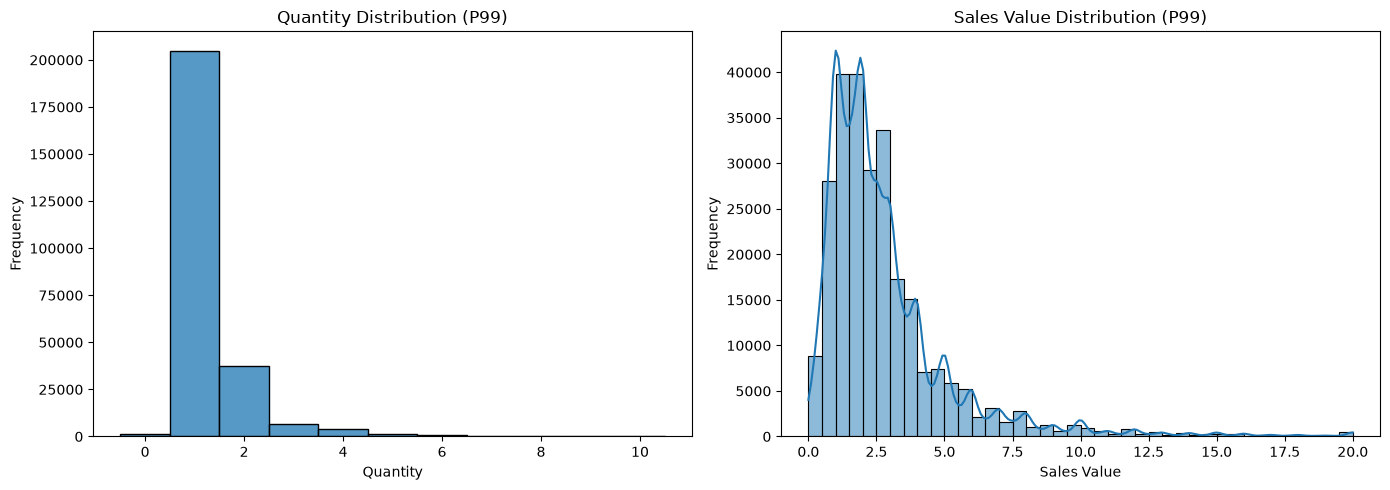

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Quantity distribution
quantity_limit = df["QUANTITY"].quantile(0.99)

sns.histplot(
    data = df.loc[df["QUANTITY"] <= quantity_limit],
    x="QUANTITY",
    discrete=True,
    ax=axes[0]
)

axes[0].set_title("Quantity Distribution (P99)")
axes[0].set_xlabel("Quantity")
axes[0].set_ylabel("Frequency")

# Sales value distribution
sales_limit = df["SALES_VALUE"].quantile(0.99)

sns.histplot(
    data=df.loc[df["SALES_VALUE"] <= sales_limit],
    x="SALES_VALUE",
    bins=40,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Sales Value Distribution (P99)")
axes[1].set_xlabel("Sales Value")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


## 1.7 Boxplot and IQR Analysis

Boxplots help us understand the spread of numerical variables and identify potential outliers.

We will calculate the interquartile range (IQR) and visualize the distributions.

We will not automatically remove outliers because some extreme values may represent valid business transactions.


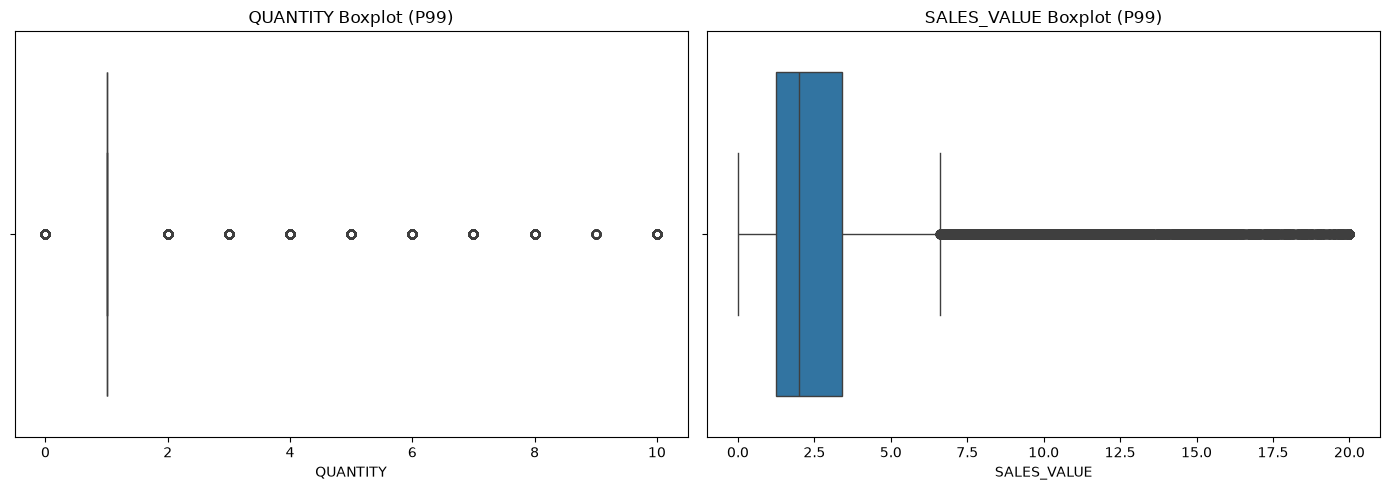

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, column in zip(axes, numerical_cols):

    upper_limit = df[column].quantile(0.99)

    plot_data = df.loc[
        df[column] <= upper_limit,
        column
    ]

    sns.boxplot(
        x=plot_data,
        ax=ax,
        showfliers=True
    )

    ax.set_title(f"{column} Boxplot (P99)")
    ax.set_xlabel(column)

plt.tight_layout()
plt.show()

In [20]:
for column in numerical_cols:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df.loc[
        (df[column] < lower_bound)
        | (df[column] > upper_bound)
    ]

    print(f"\nVariable: {column}")
    print(f"Q1: {Q1:.2f}")
    print(f"Q3: {Q3:.2f}")
    print(f"IQR: {IQR:.2f}")
    print(f"Lower Bound: {lower_bound:.2f}")
    print(f"Upper Bound: {upper_bound:.2f}")
    print(f"Potential Outliers: {len(outliers):,}")
    print(f"Outlier Ratio: {len(outliers) / len(df):.2%}")


Variable: QUANTITY
Q1: 1.00
Q3: 1.00
IQR: 0.00
Lower Bound: 1.00
Upper Bound: 1.00
Potential Outliers: 54,653
Outlier Ratio: 21.05%

Variable: SALES_VALUE
Q1: 1.29
Q3: 3.49
IQR: 2.20
Lower Bound: -2.01
Upper Bound: 6.79
Potential Outliers: 18,971
Outlier Ratio: 7.31%



## 1.8 Categorical Variable Analysis

Categorical variables describe different groups in the dataset.

In this section, we will analyze product departments and subcategories.

Our main goals are:
- Identify the most common product categories.
- Check missing or unknown categories.
- Compare transaction frequencies across departments.
- Understand customer purchasing patterns.


In [21]:
categorical_cols = [
    "DEPARTMENT",
    "SUB_COMMODITY_DESC",
]

# Create a separate DataFrame
df_cat = df[categorical_cols].copy()

# Clean categorical variables
for col in categorical_cols:
    df_cat[col] = (
        df_cat[col]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
        .fillna("Unknown")
    )

# Count unique categories
category_summary = pd.DataFrame({
    "variable": categorical_cols,
    "unique_categories": [
        df_cat[col].nunique()
        for col in categorical_cols
    ],
    "unknown_count": [
        df_cat[col].eq("Unknown").sum()
        for col in categorical_cols
    ],
})

display(category_summary)

,variable,unique_categories,unknown_count
0,DEPARTMENT,33,765
1,SUB_COMMODITY_DESC,2002,765


In [22]:

department_counts = (
    df_cat["DEPARTMENT"]
    .value_counts()
    .head(10)
)

display(department_counts)


DEPARTMENT
GROCERY          164297
DRUG GM           27890
PRODUCE           25818
MEAT-PCKGD        11333
MEAT               8781
DELI               6276
PASTRY             3783
NUTRITION          3288
KIOSK-GAS          2184
SEAFOOD-PCKGD      1085
Name: count, dtype: Int64

In [23]:
(
    df_cat["DEPARTMENT"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

DEPARTMENT
GROCERY           63.30
DRUG GM           10.74
PRODUCE            9.95
MEAT-PCKGD         4.37
MEAT               3.38
DELI               2.42
PASTRY             1.46
NUTRITION          1.27
KIOSK-GAS          0.84
SEAFOOD-PCKGD      0.42
SALAD BAR          0.35
COSMETICS          0.30
Unknown            0.29
MISC SALES TRAN    0.24
FLORAL             0.16
SEAFOOD            0.16
MISC. TRANS.       0.10
SPIRITS            0.09
COUP/STR & MFG     0.04
TRAVEL & LEISUR    0.03
CHEF SHOPPE        0.03
GARDEN CENTER      0.03
RESTAURANT         0.02
FROZEN GROCERY     0.01
DAIRY DELI         0.00
AUTOMOTIVE         0.00
PHOTO              0.00
RX                 0.00
POSTAL CENTER      0.00
MEAT-WHSE          0.00
VIDEO RENTAL       0.00
GM MERCH EXP       0.00
PHARMACY SUPPLY    0.00
Name: proportion, dtype: Float64


### 1.8.1 Department Sales Performance

Transaction frequency does not always represent sales performance.

In this section, we will compare departments based on:
- Number of transaction lines
- Total sales value
- Average sales value per transaction line
- Transaction share
- Sales share

This analysis will help us understand the differences between purchase frequency and sales performance.


In [24]:
# Create a separate DataFrame for department analysis
department_df = df.copy()

# Use the cleaned department categories
department_df["DEPARTMENT"] = df_cat["DEPARTMENT"]

# Calculate department-level metrics
department_summary = (
    department_df
    .groupby("DEPARTMENT")
    .agg(
        transaction_count=("SALES_VALUE", "size"),
        total_sales=("SALES_VALUE", "sum"),
        avg_sales=("SALES_VALUE", "mean"),
    )
)

# Calculate transaction and sales shares
department_summary["transaction_share"] = (
    department_summary["transaction_count"]
    / department_summary["transaction_count"].sum()
    * 100
)

department_summary["sales_share"] = (
    department_summary["total_sales"]
    / department_summary["total_sales"].sum()
    * 100
)

# Sort by total sales
department_summary = (
    department_summary
    .sort_values("total_sales", ascending=False)
    .round(2)
)

display(department_summary.head(10))

,transaction_count,total_sales,avg_sales,transaction_share,sales_share
DEPARTMENT,,,,,
GROCERY,164297,"407,525.05",2.48,63.30,50.72
DRUG GM,27890,"105,865.18",3.80,10.74,13.18
PRODUCE,25818,"55,991.74",2.17,9.95,6.97
MEAT,8781,"54,580.14",6.22,3.38,6.79
KIOSK-GAS,2184,"53,677.63",24.58,0.84,6.68
MEAT-PCKGD,11333,"41,801.37",3.69,4.37,5.20
DELI,6276,"26,037.35",4.15,2.42,3.24
MISC SALES TRAN,621,"11,976.32",19.29,0.24,1.49
PASTRY,3783,"11,683.15",3.09,1.46,1.45



### 1.8.2 Department Performance Visualization

In this section, we compare transaction share and sales share across departments.

A department with a high transaction share does not always have a high sales share.

We will use a grouped bar chart to identify differences between purchase frequency and sales performance.


In [25]:
# Select the top 10 departments by total sales
top_departments = (
    department_summary
    .head(10)
    .reset_index()
)

# Convert wide data into long format
plot_df = top_departments.melt(
    id_vars="DEPARTMENT",
    value_vars=[
        "transaction_share",
        "sales_share"
    ],
    var_name="metric",
    value_name="share_pct"
)

plot_df

,DEPARTMENT,metric,share_pct
0,GROCERY,transaction_share,63.30
1,DRUG GM,transaction_share,10.74
2,PRODUCE,transaction_share,9.95
3,MEAT,transaction_share,3.38
4,KIOSK-GAS,transaction_share,0.84
5,MEAT-PCKGD,transaction_share,4.37
6,DELI,transaction_share,2.42
7,MISC SALES TRAN,transaction_share,0.24
8,PASTRY,transaction_share,1.46
9,NUTRITION,transaction_share,1.27


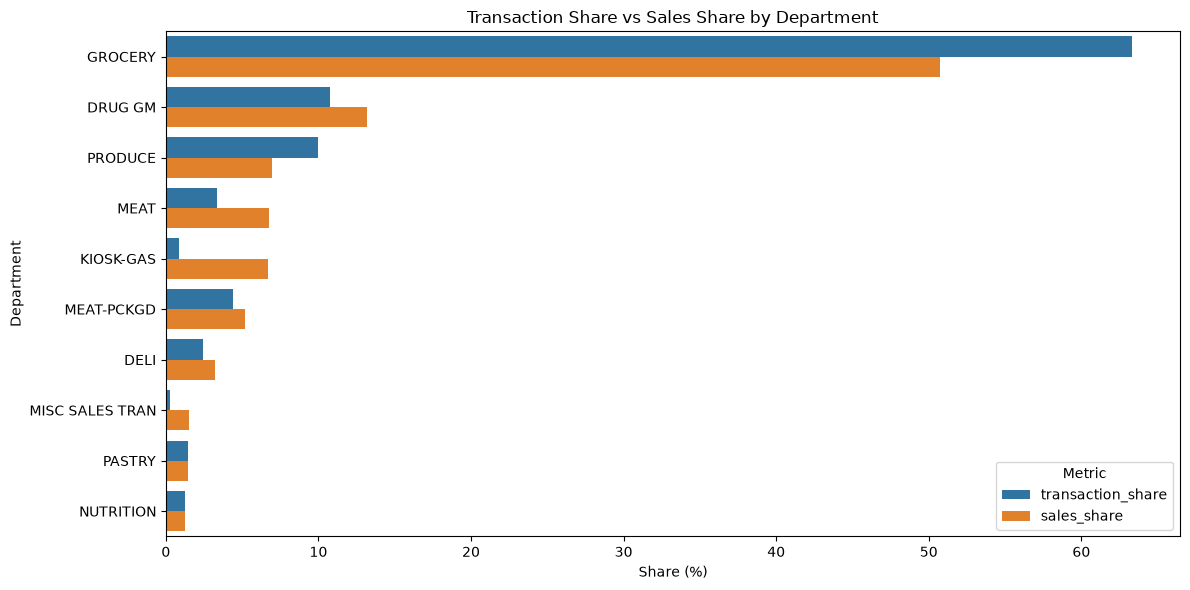

In [26]:
# Create the visualization
plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_df,
    x="share_pct",
    y="DEPARTMENT",
    hue="metric",
    order=top_departments["DEPARTMENT"],
    errorbar=None
)

plt.title("Transaction Share vs Sales Share by Department")
plt.xlabel("Share (%)")
plt.ylabel("Department")
plt.legend(title="Metric")

plt.tight_layout()
plt.show()


## 1.9 Customer-Level Analysis

In this section, we will analyze customer purchasing behavior.

We will first aggregate transaction lines into shopping baskets.

Then, we will calculate customer-level metrics such as:
- Purchase frequency
- Total spending
- Average basket value
- Number of active shopping days

These metrics will also support future CRM analytics and machine learning models.


In [27]:
query = text("""
    SELECT
        household_key,
        BASKET_ID,

        MIN(`DAY`) AS basket_day,
        COUNT(DISTINCT `DAY`) AS distinct_days,

        COUNT(*) AS basket_lines,

        COUNT(DISTINCT PRODUCT_ID) AS unique_products,

        SUM(SALES_VALUE) AS basket_sales

    FROM raw_transaction_data

    GROUP BY
        household_key,
        BASKET_ID
""")

with engine.connect() as connection:
    basket_df = pd.read_sql_query(
        query,
        con=connection
    )

# Convert sales values to numeric format for analysis
basket_df["basket_sales"] = pd.to_numeric(
    basket_df["basket_sales"]
)

print("Basket dataset shape:", basket_df.shape)

display(basket_df.head(10))

Basket dataset shape: (276484, 7)


,household_key,BASKET_ID,basket_day,distinct_days,basket_lines,unique_products,basket_sales
0,1,27601281299,51,1,30,30,78.66
1,1,27774192959,67,1,12,12,41.10
2,1,28024266849,88,1,12,12,26.90
3,1,28106322445,94,1,23,23,63.43
4,1,28235481967,101,1,17,17,53.45
5,1,28282581446,108,1,10,10,26.76
6,1,28318295376,111,1,9,9,23.55
7,1,28601601153,128,1,39,39,110.34
8,1,28744672720,137,1,36,36,87.44
9,1,28853646373,146,1,29,29,73.32


In [28]:
print("Total baskets:", len(basket_df))

print(
    "Unique households:",
    basket_df["household_key"].nunique()
)

print(
    "Zero-value baskets:",
    (basket_df["basket_sales"] == 0).sum()
)

print(
    "Baskets with multiple days:",
    (basket_df["distinct_days"] > 1).sum()
)

display(
    basket_df[
        ["basket_lines", "unique_products", "basket_sales"]
    ].describe().T
)

Total baskets: 276484
Unique households: 2500
Zero-value baskets: 942
Baskets with multiple days: 0


,count,mean,std,min,25%,50%,75%,max
basket_lines,"276,484.00",9.39,12.28,1.00,2.00,5.00,12.00,168.00
unique_products,"276,484.00",9.39,12.28,1.00,2.00,5.00,12.00,168.00
basket_sales,"276,484.00",29.14,36.10,0.00,6.96,17.07,36.28,961.49



### 1.9.1 Customer-Level Aggregation

We will create a customer-level dataset from shopping baskets.

Each row will represent one household.

We will calculate:
- Total number of baskets
- Purchase frequency
- Total spending
- Average basket value
- Number of active shopping days
- First and last purchase days

We will keep zero-value baskets but exclude them from purchase frequency calculations.


In [29]:
# 1. Aggregate all baskets by household
customer_all = (
    basket_df
    .groupby("household_key", as_index=False)
    .agg(
        total_baskets=("BASKET_ID", "nunique"),
        total_spending=("basket_sales", "sum"),
    )
)

# 2. Select baskets with positive sales
positive_baskets = basket_df.loc[
    basket_df["basket_sales"] > 0
].copy()

# 3. Calculate purchase-related metrics
customer_purchases = (
    positive_baskets
    .groupby("household_key", as_index=False)
    .agg(
        purchase_frequency=("BASKET_ID", "nunique"),
        avg_basket_value=("basket_sales", "mean"),
        active_days=("basket_day", "nunique"),
        first_purchase_day=("basket_day", "min"),
        last_purchase_day=("basket_day", "max"),
    )
)

# 4. Merge both customer tables
customer_df = customer_all.merge(
    customer_purchases,
    on="household_key",
    how="left",
    validate="one_to_one",
)

# 5. Calculate zero-value basket counts
customer_df["purchase_frequency"] = (
    customer_df["purchase_frequency"]
    .fillna(0)
    .astype(int)
)

customer_df["zero_value_baskets"] = (
    customer_df["total_baskets"]
    - customer_df["purchase_frequency"]
)

print("Customer dataset shape:", customer_df.shape)

display(customer_df.head())

Customer dataset shape: (2500, 9)


,household_key,total_baskets,total_spending,purchase_frequency,avg_basket_value,active_days,first_purchase_day,last_purchase_day,zero_value_baskets
0,1,86,"4,330.16",85,50.94,78,51,706,1
1,2,45,"1,954.34",45,43.43,45,103,668,0
2,3,47,"2,653.21",47,56.45,46,113,703,0
3,4,30,"1,200.11",30,40.00,30,104,627,0
4,5,40,779.06,40,19.48,33,85,703,0


In [30]:

print("Total customers:", len(customer_df))

print(
    "Total baskets:",
    customer_df["total_baskets"].sum()
)

print(
    "Positive baskets:",
    customer_df["purchase_frequency"].sum()
)

print(
    "Zero-value baskets:",
    customer_df["zero_value_baskets"].sum()
)

customer_metrics = [
    "purchase_frequency",
    "total_spending",
    "avg_basket_value",
    "active_days",
]

display(
    customer_df[customer_metrics]
    .describe()
    .T
    .round(2)
)


Total customers: 2500
Total baskets: 276484
Positive baskets: 275542
Zero-value baskets: 942


,count,mean,std,min,25%,50%,75%,max
purchase_frequency,"2,500.00",110.22,115.27,1.00,38.00,78.00,142.00,"1,298.00"
total_spending,"2,500.00","3,222.99","3,349.03",8.17,970.74,"2,157.75","4,413.32","38,319.79"
avg_basket_value,"2,500.00",31.73,19.12,2.39,18.43,27.49,40.62,165.83
active_days,"2,500.00",90.11,76.26,1.00,34.00,70.00,124.00,521.00



### 1.9.2 Customer Behavior Distribution

In this section, we analyze the distribution of customer-level metrics.

We focus on:
- Purchase frequency
- Total spending
- Average basket value

We will calculate descriptive statistics and visualize the distributions.

The goal is to understand differences in customer behavior before CRM analytics and machine learning.


In [31]:

customer_metrics = [
    "purchase_frequency",
    "total_spending",
    "avg_basket_value",
]

customer_summary = (
    customer_df[customer_metrics]
    .describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
    .T
)

# Calculate skewness for each variable
customer_summary["skewness"] = (
    customer_df[customer_metrics].skew()
)

display(customer_summary.round(2))


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skewness
purchase_frequency,"2,500.00",110.22,115.27,1.00,5.00,11.00,38.00,78.00,142.00,320.05,552.11,"1,298.00",3.38
total_spending,"2,500.00","3,222.99","3,349.03",8.17,84.21,240.81,970.74,"2,157.75","4,413.32","9,754.14","15,325.02","38,319.79",2.41
avg_basket_value,"2,500.00",31.73,19.12,2.39,6.25,9.90,18.43,27.49,40.62,67.60,99.64,165.83,1.72


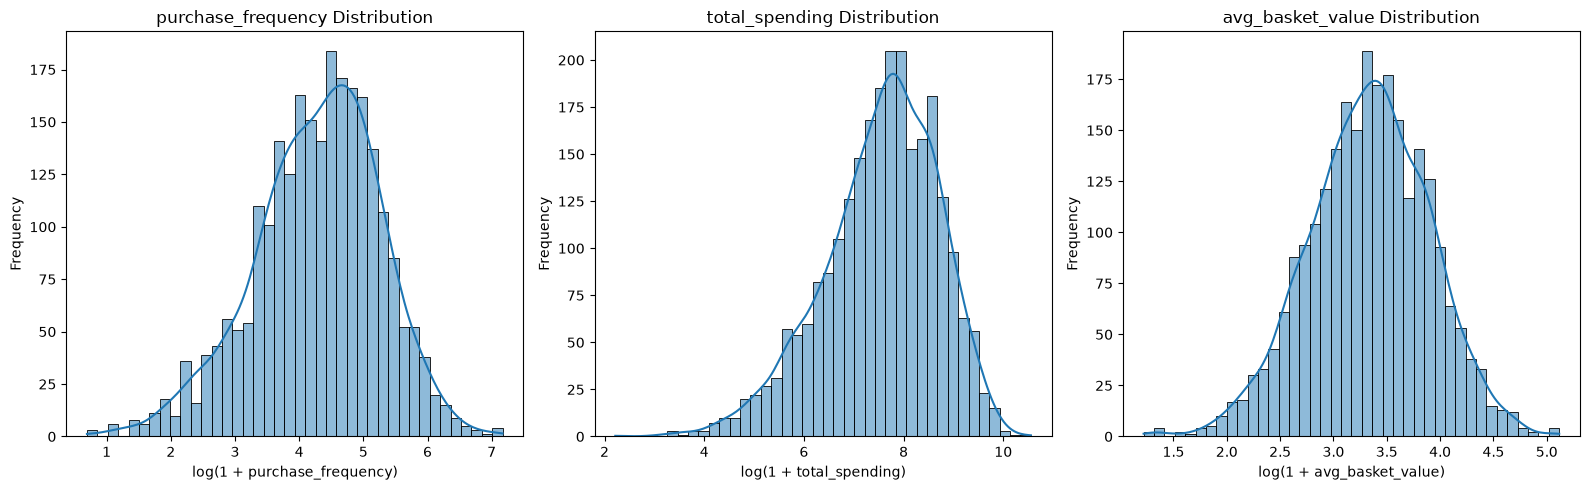

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, column in zip(axes, customer_metrics):

    # Apply log transformation for visualization
    log_values = np.log1p(customer_df[column]).dropna()

    sns.histplot(
        x=log_values,
        bins=40,
        kde=True,
        ax=ax
    )

    ax.set_title(f"{column} Distribution")
    ax.set_xlabel(f"log(1 + {column})")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


## 1.10 Time-Based Analysis

In this section, we will analyze daily retail activity.

Our main goals are:
- Understand daily sales trends.
- Measure the number of shopping baskets.
- Track daily active customers.
- Identify changes in customer activity over time.

We will also use a 7-day moving average to better understand sales trends.


In [33]:
basket_df.head()

,household_key,BASKET_ID,basket_day,distinct_days,basket_lines,unique_products,basket_sales
0,1,27601281299,51,1,30,30,78.66
1,1,27774192959,67,1,12,12,41.10
2,1,28024266849,88,1,12,12,26.90
3,1,28106322445,94,1,23,23,63.43
4,1,28235481967,101,1,17,17,53.45


In [34]:
daily_df = (
    basket_df
    .groupby("basket_day", as_index=False)
    .agg(
        total_sales=("basket_sales", "sum"),
        total_baskets=("BASKET_ID", "nunique"),
        active_customers=("household_key", "nunique"),
    )
    .sort_values("basket_day")
)

# Calculate average basket value
daily_df["avg_basket_value"] = (
    daily_df["total_sales"] / daily_df["total_baskets"]
)

# Calculate 7-day moving average
daily_df["sales_ma7"] = (
    daily_df["total_sales"]
    .rolling(window=7, min_periods=1)
    .mean()
)

display(daily_df.head(10))

,basket_day,total_sales,total_baskets,active_customers,avg_basket_value,sales_ma7
0,1,549.31,16,15,34.33,549.31
1,2,458.91,13,12,35.30,504.11
2,3,"1,560.37",44,33,35.46,856.20
3,4,"1,785.64",44,36,40.58,"1,088.56"
4,5,856.93,25,23,34.28,"1,042.23"
5,6,"1,008.15",37,28,27.25,"1,036.55"
6,7,"1,271.29",34,27,37.39,"1,070.09"
7,8,"1,203.85",43,34,28.00,"1,163.59"
8,9,"1,050.95",39,31,26.95,"1,248.17"
9,10,"1,714.38",51,42,33.62,"1,270.17"


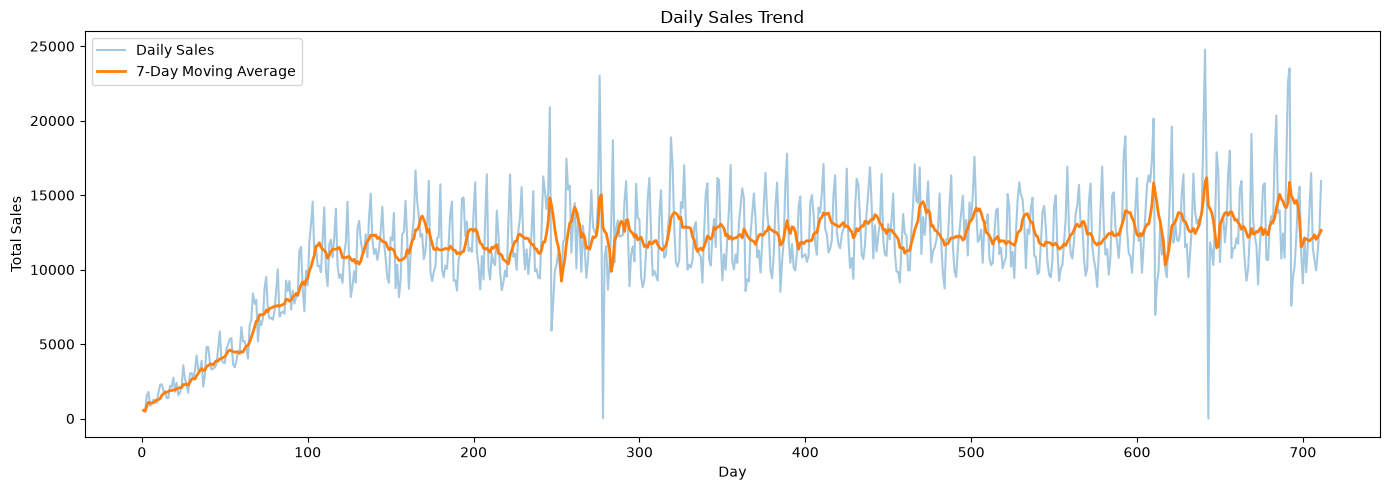

In [35]:

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=daily_df,
    x="basket_day",
    y="total_sales",
    label="Daily Sales",
    alpha=0.4,
)

sns.lineplot(
    data=daily_df,
    x="basket_day",
    y="sales_ma7",
    label="7-Day Moving Average",
    linewidth=2,
)

plt.title("Daily Sales Trend")
plt.xlabel("Day")
plt.ylabel("Total Sales")
plt.legend()
plt.tight_layout()
plt.show()



### 1.10.1 Investigation of Unusual Sales Days

The daily sales chart shows a strong increase during the first 100 days and unusual drops in later periods.

We will investigate these patterns by comparing:
- Daily sales
- Shopping basket counts
- Active customer counts
- Average basket values

We will also check whether any days are missing from the dataset.


In [36]:
# 1. Check missing days
expected_days = set(range(1, 712))
observed_days = set(daily_df["basket_day"])

missing_days = sorted(expected_days - observed_days)

print("Observed days:", len(observed_days))
print("Missing days:", missing_days)

# 2. Calculate sales per active customer
daily_df["sales_per_customer"] = (
    daily_df["total_sales"]
    / daily_df["active_customers"].replace(0,np.nan)
)

# 3. Focus on the period after day 100
analysis_df = daily_df.loc[
    daily_df["basket_day"] >= 100
].copy()

# 4. Find the days with the lowest sales
lowest_sales_days = analysis_df.nsmallest(
    10,
    "total_sales"
)

display(
    lowest_sales_days[
        [
            "basket_day",
            "total_sales",
            "total_baskets",
            "active_customers",
            "avg_basket_value",
            "sales_per_customer",
        ]
    ]
)

Observed days: 711
Missing days: []


,basket_day,total_sales,total_baskets,active_customers,avg_basket_value,sales_per_customer
642,643,2.99,1,1,2.99,2.99
277,278,22.49,1,1,22.49,22.49
246,247,"5,905.22",292,241,20.22,24.50
610,611,"6,962.69",324,264,21.49,26.37
692,693,"7,573.73",276,233,27.44,32.51
247,248,"7,785.53",329,258,23.66,30.18
154,155,"8,147.01",379,312,21.50,26.11
125,126,"8,154.52",376,304,21.69,26.82
384,385,"8,515.04",339,295,25.12,28.86
363,364,"8,555.63",337,285,25.39,30.02


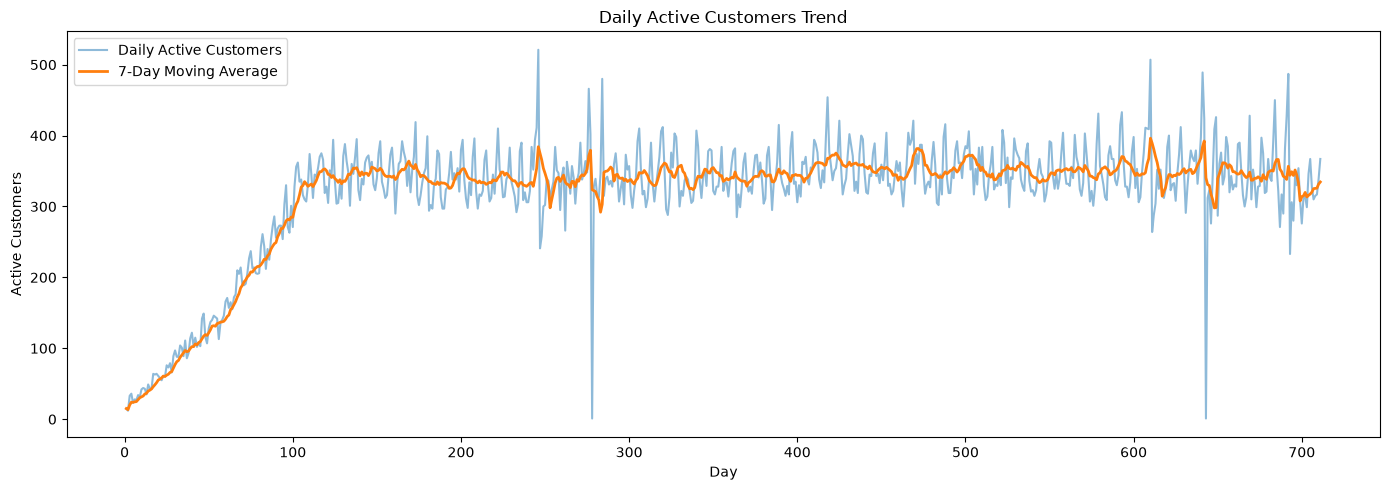

In [37]:

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=daily_df,
    x="basket_day",
    y="active_customers",
    label="Daily Active Customers",
    alpha=0.5,
)

daily_df["customers_ma7"] = (
    daily_df["active_customers"]
    .rolling(window=7, min_periods=1)
    .mean()
)

sns.lineplot(
    data=daily_df,
    x="basket_day",
    y="customers_ma7",
    label="7-Day Moving Average",
    linewidth=2,
)

plt.title("Daily Active Customers Trend")
plt.xlabel("Day")
plt.ylabel("Active Customers")
plt.legend()
plt.tight_layout()
plt.show()



### 1.10.2 Investigation of Repeated Sales Anomalies

We identified two unusual days with only one active customer.

These days are exactly 365 days apart.

We will compare each day with its surrounding days to understand how unusual the customer activity is.

This analysis may help us identify recurring business events or possible data quality issues.


In [38]:
anomaly_days = [278, 643]

for target_day in anomaly_days:

    # Select three days before and after the target day
    window_df = daily_df.loc[
        daily_df["basket_day"].between(
            target_day - 3,
            target_day + 3
        ),
        [
            "basket_day",
            "total_sales",
            "total_baskets",
            "active_customers",
            "avg_basket_value"
        ]
    ].copy()

    # Exclude the anomaly day from baseline calculation
    baseline_df = window_df.loc[
        window_df["basket_day"] != target_day
    ]

    baseline_customers = (
        baseline_df["active_customers"].median()
    )

    actual_customers = window_df.loc[
        window_df["basket_day"] == target_day,
        "active_customers"
    ].iloc[0]

    customer_drop_pct = (
        (1 - actual_customers / baseline_customers) * 100
    )

    print(f"\nTarget Day: {target_day}")
    print(f"Baseline Customers: {baseline_customers:.0f}")
    print(f"Actual Customers: {actual_customers}")
    print(f"Customer Drop: {customer_drop_pct:.2f}%")

    display(window_df)



Target Day: 278
Baseline Customers: 344
Actual Customers: 1
Customer Drop: 99.71%


,basket_day,total_sales,total_baskets,active_customers,avg_basket_value
274,275,"14,520.57",424,348,34.25
275,276,"23,018.88",582,466,39.55
276,277,"14,635.13",497,402,29.45
277,278,22.49,1,1,22.49
278,279,"10,859.11",409,328,26.55
279,280,"11,583.51",410,339,28.25
280,281,"8,657.83",370,315,23.40



Target Day: 643
Baseline Customers: 360
Actual Customers: 1
Customer Drop: 99.72%


,basket_day,total_sales,total_baskets,active_customers,avg_basket_value
639,640,"19,095.37",480,398,39.78
640,641,"24,760.10",628,489,39.43
641,642,"16,005.20",513,423,31.20
642,643,2.99,1,1,2.99
643,644,"11,830.28",377,312,31.38
644,645,"11,304.24",395,323,28.62
645,646,"10,303.79",348,276,29.61



### 1.10.3 Weekly Sales Analysis

Daily sales show strong fluctuations and some unusual observations.

In this section, we will aggregate transactions by week.

We will analyze:
- Weekly total sales
- Weekly shopping baskets
- Weekly active customers
- Average daily sales within each week

We will also calculate a four-week moving average to understand the general sales trend.


In [39]:

query = text("""
    SELECT
        WEEK_NO AS week_no,
        MIN(`DAY`) AS first_day,
        MAX(`DAY`) AS last_day,

        COUNT(DISTINCT `DAY`) AS observed_days,

        ROUND(SUM(SALES_VALUE), 2) AS total_sales,

        COUNT(DISTINCT BASKET_ID) AS total_baskets,

        COUNT(DISTINCT household_key) AS active_customers

    FROM raw_transaction_data

    GROUP BY WEEK_NO
    ORDER BY WEEK_NO
""")

with engine.connect() as connection:
    weekly_df = pd.read_sql_query(
        query,
        con=connection
    )

# Convert sales values to numeric
weekly_df["total_sales"] = pd.to_numeric(
    weekly_df["total_sales"]
)

# Calculate average sales per observed day
weekly_df["sales_per_day"] = (
    weekly_df["total_sales"]
    / weekly_df["observed_days"]
)

# Calculate average basket value
weekly_df["avg_basket_value"] = (
    weekly_df["total_sales"]
    / weekly_df["total_baskets"]
)

# Calculate four-week moving average
weekly_df["sales_ma4"] = (
    weekly_df["total_sales"]
    .rolling(window=4, min_periods=4)
    .mean()
)

print("Weekly dataset shape:", weekly_df.shape)

display(weekly_df.head(10))


Weekly dataset shape: (102, 10)


,week_no,first_day,last_day,observed_days,total_sales,total_baskets,active_customers,sales_per_day,avg_basket_value,sales_ma4
0,1,1,5,5,"5,211.16",142,88,"1,042.23",36.70,NaN
1,2,6,12,7,"10,821.35",324,175,"1,545.91",33.40,NaN
2,3,13,19,7,"13,498.20",482,228,"1,928.31",28.00,NaN
3,4,20,26,7,"15,965.99",545,270,"2,280.86",29.30,"11,374.17"
4,5,27,33,7,"20,139.82",757,370,"2,877.12",26.60,"15,106.34"
5,6,34,40,7,"24,923.90",861,433,"3,560.56",28.95,"18,631.98"
6,7,41,47,7,"28,073.97",999,491,"4,010.57",28.10,"22,275.92"
7,8,48,54,7,"31,793.77",1086,530,"4,541.97",29.28,"26,232.86"
8,9,55,61,7,"31,244.17",1212,622,"4,463.45",25.78,"29,008.95"
9,10,62,68,7,"42,994.38",1553,708,"6,142.05",27.68,"33,526.57"


In [40]:

print("Number of weeks:", weekly_df["week_no"].nunique())

print(
    "Week range:",
    weekly_df["week_no"].min(),
    "-",
    weekly_df["week_no"].max()
)

print("\nObserved days per week:")
print(
    weekly_df["observed_days"]
    .value_counts()
    .sort_index()
)

print("\nWeeks with fewer than 7 observed days:")

display(
    weekly_df.loc[
        weekly_df["observed_days"] < 7,
        ["week_no", "first_day", "last_day", "observed_days"]
    ]
)


Number of weeks: 102
Week range: 1 - 102

Observed days per week:
observed_days
5      1
6      1
7    100
Name: count, dtype: int64

Weeks with fewer than 7 observed days:


,week_no,first_day,last_day,observed_days
0,1,1,5,5
101,102,706,711,6



### 1.10.4 Weekly Sales and Customer Trends

We will visualize weekly sales and active customers.

We will use only complete weeks to make fair comparisons.

A four-week moving average will help us identify general trends and reduce short-term fluctuations.

We will compare sales activity with customer participation over time.


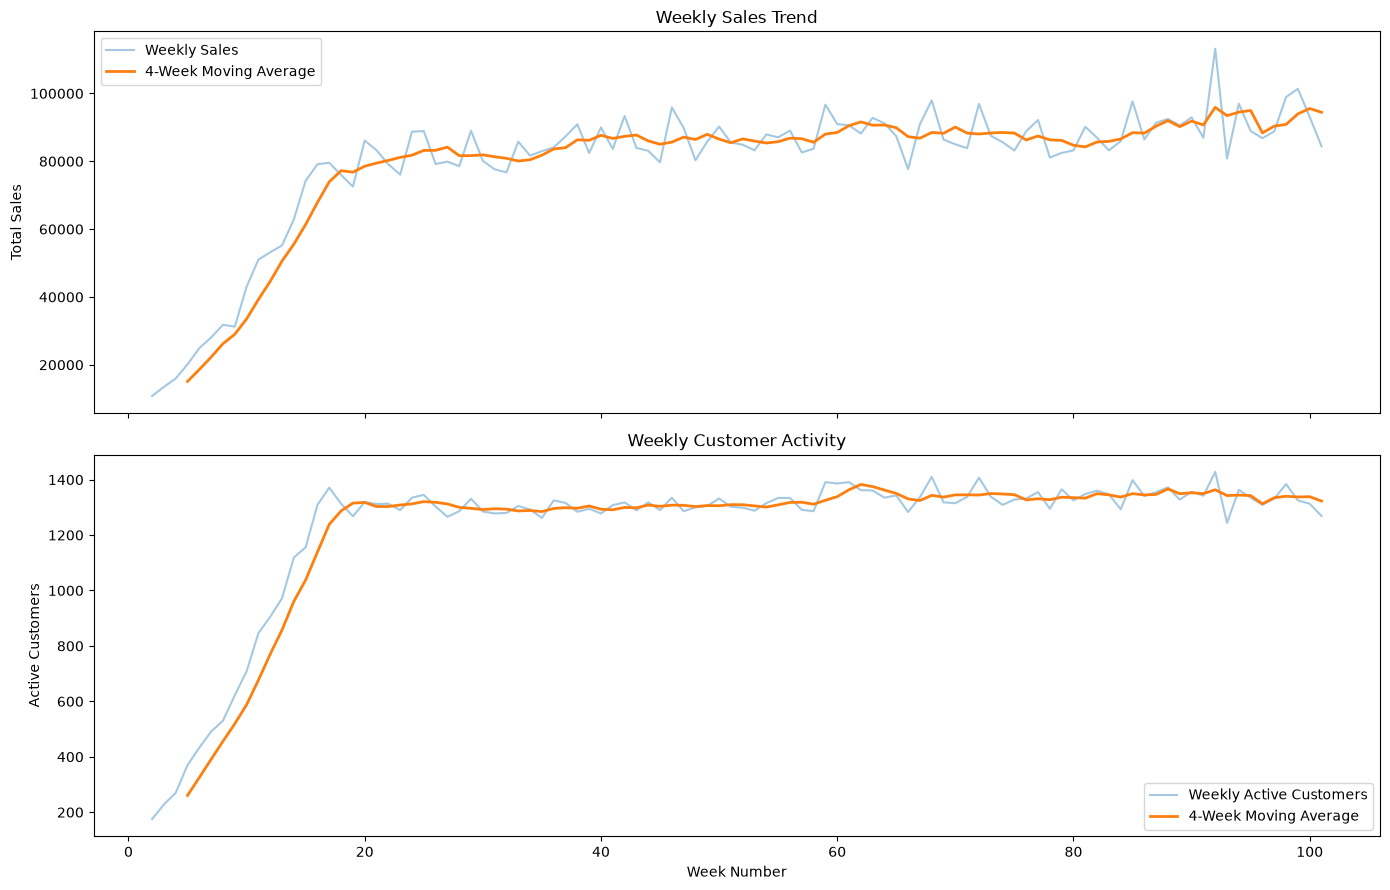

In [41]:

# Select complete weeks
weekly_complete = (
    weekly_df.loc[
        weekly_df["observed_days"].eq(7)
    ]
    .sort_values("week_no")
    .copy()
)

# Calculate a 4-week moving average
weekly_complete["sales_ma4"] = (
    weekly_complete["total_sales"]
    .rolling(window=4, min_periods=4)
    .mean()
)

# Calculate the moving average of active customers
weekly_complete["customers_ma4"] = (
    weekly_complete["active_customers"]
    .rolling(window=4, min_periods=4)
    .mean()
)

# Create two charts
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 9),
    sharex=True
)

# Weekly sales
sns.lineplot(
    data=weekly_complete,
    x="week_no",
    y="total_sales",
    ax=axes[0],
    label="Weekly Sales",
    alpha=0.4
)

sns.lineplot(
    data=weekly_complete,
    x="week_no",
    y="sales_ma4",
    ax=axes[0],
    label="4-Week Moving Average",
    linewidth=2
)

axes[0].set_title("Weekly Sales Trend")
axes[0].set_ylabel("Total Sales")

# Weekly active customers
sns.lineplot(
    data=weekly_complete,
    x="week_no",
    y="active_customers",
    ax=axes[1],
    label="Weekly Active Customers",
    alpha=0.4
)

sns.lineplot(
    data=weekly_complete,
    x="week_no",
    y="customers_ma4",
    ax=axes[1],
    label="4-Week Moving Average",
    linewidth=2
)

axes[1].set_title("Weekly Customer Activity")
axes[1].set_xlabel("Week Number")
axes[1].set_ylabel("Active Customers")

plt.tight_layout()
plt.show()



### 1.10.5 Weekly Seasonality Analysis

Daily sales may follow a repeating seven-day pattern.

In this section, we will compare sales and customer activity across the seven positions of a weekly cycle.

We will use median values to reduce the influence of unusual days.

The analysis will help us identify possible weekly seasonality in retail activity.


In [42]:
# Focus on the period after the initial growth phase
cycle_df = daily_df.loc[
    daily_df["basket_day"] >= 100
].copy()

# Create a seven-day cycle variable
cycle_df["cycle_day"] = (
    (cycle_df["basket_day"] - 1) % 7
)

# Calculate statistics for each cycle day
cycle_summary = (
    cycle_df
    .groupby("cycle_day", as_index=False)
    .agg(
        observed_days=("basket_day", "nunique"),
        mean_sales=("total_sales", "mean"),
        median_sales=("total_sales", "median"),
        median_customers=("active_customers", "median"),
        median_baskets=("total_baskets", "median"),
    )
    .sort_values("cycle_day")
)

display(cycle_summary.round(2))

,cycle_day,observed_days,mean_sales,median_sales,median_customers,median_baskets
0,0,87,"10,827.70","10,778.70",323.00,391.00
1,1,88,"10,919.23","10,584.39",326.50,395.00
2,2,88,"12,097.81","12,008.50",337.50,413.00
3,3,88,"14,618.19","14,253.28",375.00,471.00
4,4,87,"15,221.02","15,366.25",387.00,481.00
5,5,87,"12,026.54","11,961.96",345.00,421.00
6,6,87,"11,037.48","10,856.46",325.00,391.00


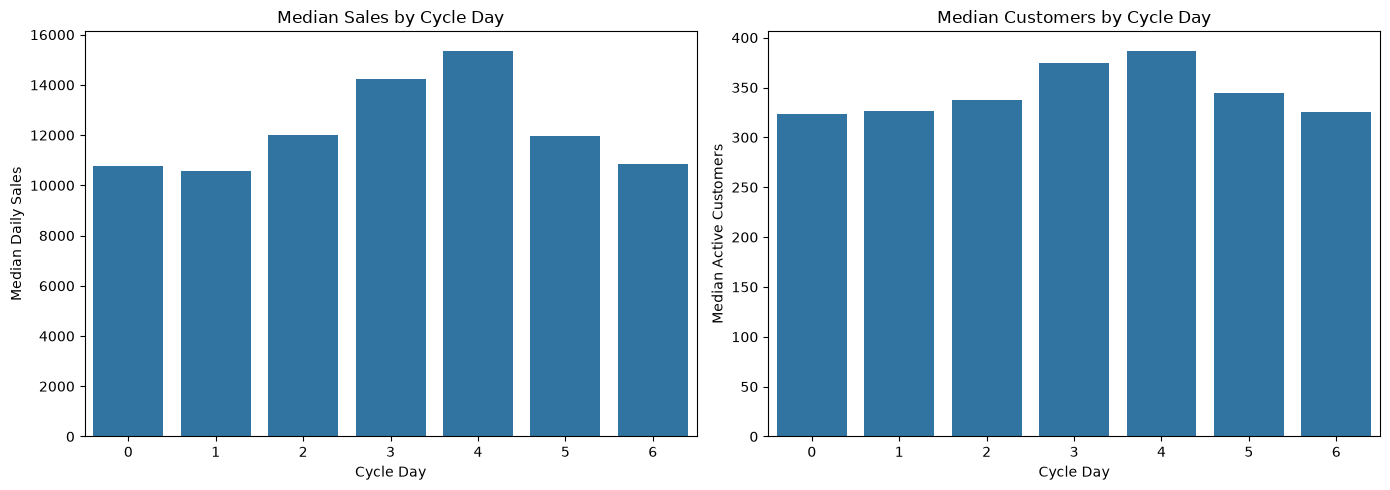

In [43]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Median daily sales by cycle day
sns.barplot(
    data=cycle_summary,
    x="cycle_day",
    y="median_sales",
    ax=axes[0],
    errorbar=None
)

axes[0].set_title("Median Sales by Cycle Day")
axes[0].set_xlabel("Cycle Day")
axes[0].set_ylabel("Median Daily Sales")

# Median active customers by cycle day
sns.barplot(
    data=cycle_summary,
    x="cycle_day",
    y="median_customers",
    ax=axes[1],
    errorbar=None
)

axes[1].set_title("Median Customers by Cycle Day")
axes[1].set_xlabel("Cycle Day")
axes[1].set_ylabel("Median Active Customers")

plt.tight_layout()
plt.show()



## 1.11 Correlation Analysis

In this section, we will investigate relationships between customer behavior metrics.

We will use two correlation methods:

- Pearson correlation measures linear relationships.
- Spearman correlation measures monotonic relationships using ranks.

Our main goals are to identify relationships between purchase frequency, spending, basket value, and active shopping days.

We will compare both methods because our customer variables have right-skewed distributions.


In [44]:
customer_df.head()

,household_key,total_baskets,total_spending,purchase_frequency,avg_basket_value,active_days,first_purchase_day,last_purchase_day,zero_value_baskets
0,1,86,"4,330.16",85,50.94,78,51,706,1
1,2,45,"1,954.34",45,43.43,45,103,668,0
2,3,47,"2,653.21",47,56.45,46,113,703,0
3,4,30,"1,200.11",30,40.00,30,104,627,0
4,5,40,779.06,40,19.48,33,85,703,0


In [45]:

# Select customer-level numerical variables
correlation_cols = [
    "purchase_frequency",
    "total_spending",
    "avg_basket_value",
    "active_days",
]

correlation_df = customer_df[correlation_cols].copy()

# Calculate Pearson correlation
pearson_corr = correlation_df.corr(method="pearson")

# Calculate Spearman correlation
spearman_corr = correlation_df.corr(method="spearman")

print("PEARSON CORRELATION")
display(pearson_corr.round(3))

print("SPEARMAN CORRELATION")
display(spearman_corr.round(3))


PEARSON CORRELATION


,purchase_frequency,total_spending,avg_basket_value,active_days
purchase_frequency,1.00,0.70,-0.12,0.95
total_spending,0.70,1.00,0.39,0.75
avg_basket_value,-0.12,0.39,1.00,-0.10
active_days,0.95,0.75,-0.10,1.00


SPEARMAN CORRELATION


,purchase_frequency,total_spending,avg_basket_value,active_days
purchase_frequency,1.00,0.84,-0.04,0.99
total_spending,0.84,1.00,0.45,0.85
avg_basket_value,-0.04,0.45,1.00,-0.03
active_days,0.99,0.85,-0.03,1.00


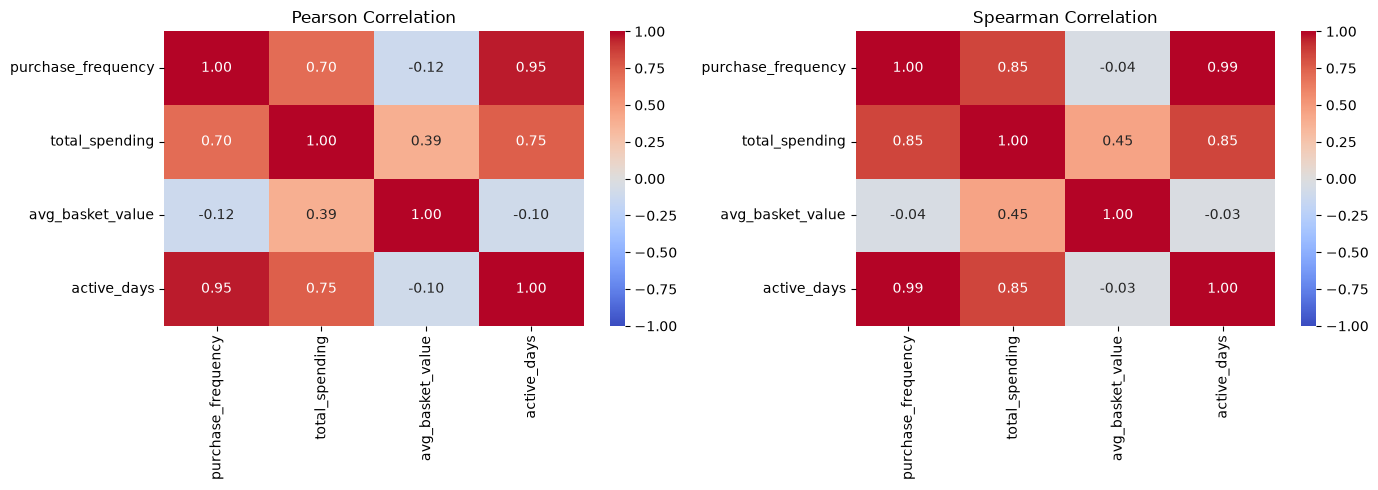

In [46]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    ax=axes[0]
)

axes[0].set_title("Pearson Correlation")

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    ax=axes[1]
)

axes[1].set_title("Spearman Correlation")

plt.tight_layout()
plt.show()



## 1.12 Key Findings and Conclusions

The exploratory data analysis provided several important insights.

**Key Findings:**

1. The dataset contains 2,500 households and 276,484 shopping baskets.
2. Quantity and sales value have highly right-skewed distributions.
3. Extremely high quantity values are mainly related to gasoline transactions.
4. Grocery products represent the largest share of transaction lines.
5. Customer purchase frequency and total spending are also right-skewed.
6. Daily and weekly sales show a strong growth period followed by more stable activity.
7. The dataset shows a clear seven-day shopping pattern.
8. Two unusual days, 278 and 643, have almost no customer activity.
9. Purchase frequency and active shopping days have a very strong positive correlation.

**Conclusion:**

Customer behavior differs significantly across households.

Purchase frequency, spending, and recency may help us identify valuable and inactive customers.

The next step is CRM Analytics, where we will apply RFM analysis and customer segmentation.
